**DATA 620 – Web Analytics**

# Introduction

This assignment looks at word frequencies in one corpus and asks how they compare with the "typical"
frequencies of English. I chose the **Reuters-21578 news corpus**, the version that ships with NLTK.
It's a collection of business and financial newswire stories from Reuters, written in 1987 and tagged
with 90 topic categories (earnings, acquisitions, crude oil, grain, money supply, trade and so on).

I picked it because it's the kind of text a data scientist working in finance would actually mine,
and because financial news has its own shorthand: "mln," "dlrs," "pct," "shr." That shorthand
makes the last question, how this corpus differs from all words in all corpora, worth answering.
To stand in for "all corpora" I use the **Brown corpus**, also in NLTK: about a million words of
American English drawn from 15 genres, from news to romance fiction.

The questions from the assignment:

1. Choose a corpus of interest.
2. How many total unique words are in the corpus?
3. Taking the most common words, how many unique words represent half of the total words?
4. Identify the 200 highest frequency words.
5. Create a graph that shows the relative frequency of these 200 words.
6. Does the observed relative frequency of these words follow Zipf's law?
7. In what ways might the frequency of words in this corpus differ from "all words in all corpora"?

In [1]:
import re, html
from collections import Counter

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Download the corpora the first time the notebook runs (skipped if already present).
for pkg, path in [("reuters", "corpora/reuters"), ("brown", "corpora/brown"),
                  ("stopwords", "corpora/stopwords"), ("wordnet", "corpora/wordnet"), ("omw-1.4", "corpora/omw-1.4")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(pkg, quiet=True)

from nltk.corpus import reuters, brown, stopwords
from nltk.stem import WordNetLemmatizer

BLUE, GREY, ORANGE = "#1f6fb4", "#b0b0b0", "#e07b00"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6})

def show_table(df, index=False, floatfmt=None):
    """Displays a DataFrame as a Markdown table (renders as a real table in the PDF)."""
    display(Markdown(df.to_markdown(index=index, floatfmt=floatfmt or "g")))

# 1. The corpus

NLTK's copy of Reuters-21578 is the "ApteMod" split, which keeps the stories that have at least one
topic label. Each story starts with its headline in capital letters, followed by the body.

In [2]:
docs = reuters.fileids()
cats = reuters.categories()
top_cats = (pd.Series({c: len(reuters.fileids(c)) for c in cats})
              .sort_values(ascending=False).head(8))

display(Markdown(f"The corpus has **{len(docs):,} stories** in **{len(cats)} categories**. "
                 "The largest categories are shown below (a story can have more than one)."))
show_table(top_cats.rename_axis("Category").reset_index(name="Stories"))

The corpus has **10,788 stories** in **90 categories**. The largest categories are shown below (a story can have more than one).

| Category   |   Stories |
|:-----------|----------:|
| earn       |      3964 |
| acq        |      2369 |
| money-fx   |       717 |
| grain      |       582 |
| crude      |       578 |
| trade      |       485 |
| interest   |       478 |
| ship       |       286 |

In [3]:
story = reuters.raw("training/1080")
cut = story.index("stock dividends.") + len("stock dividends.")
print(story[:cut])
print(f"  [... {len(story) - cut:,} more characters of notes on restructuring charges and taxes ...]")

LSB INDUSTRIES INC &lt;LSB> 4TH QTR NET
  Shr profit five cts vs loss 2.11 dlrs
      Net profit 375,061 vs loss 10.4 mln
      Revs 39.9 mln vs 37.8 mln
      Avg shrs 6,536,008 vs 4,939,895
      12 mths
      Shr profit 47 cts vs loss 3.37 dlrs
      Net profit 2,837,288 vs loss 16.6 mln
      Revs 169.1 mln vs 149.4 mln
      Avg shrs 6,037,640 vs 4,937,378
      NOTE: primary earnings per share are based on the weighted
  average number of common and dilutive common equivalent shares
  outstanding during each period after accounting for preferred
  stock dividends.
  [... 855 more characters of notes on restructuring charges and taxes ...]


This excerpt (the start of one earnings story) shows why this corpus needs care before counting. Stories mix capitalized headlines with
normal text, abbreviations such as "U.S." have periods inside them, company tickers appear inside
HTML-escaped brackets (`&lt;ABC>`), and earnings reports are written as compact tables such as
"Shr 22 cts vs 18 cts." NLTK's built-in `reuters.words()` splits "U.S." into "U", ".", "S", "." and
turns `&lt;` into a word "lt," so I tokenize the raw text myself.

**Tokenizing rules**

- Decode the HTML entities and lowercase everything, so "OIL" in a headline and "oil" in the body
  count as the same word.
- A word is a run of letters, optionally joined by a period, apostrophe, ampersand or hyphen
  (so "u.s", "at&t" and "mid-year" each stay one word).
- A possessive "'s" is removed, so "Japan's" counts as "japan".
- Numbers are not words. They're counted separately because they're a big part of this corpus.

In [4]:
WORD = re.compile(r"[a-z]+(?:[.'&-][a-z]+)*")
NUMBER = re.compile(r"\d+(?:[.,]\d+)*")

def tokenize(text):
    text = html.unescape(text).lower()
    return [w[:-2] if w.endswith("'s") else w for w in WORD.findall(text)]

raw_texts = [reuters.raw(f) for f in docs]
tokens = [w for t in raw_texts for w in tokenize(t)]
n_numbers = sum(len(NUMBER.findall(t)) for t in raw_texts)
counts = Counter(tokens)
total = len(tokens)

display(Markdown(f"After tokenizing, the corpus has **{total:,} words** (plus {n_numbers:,} "
                 f"numbers, which are left out). Numbers make up {n_numbers / (total + n_numbers):.0%} "
                 "of all word and number tokens, a sign of how numeric financial news is."))

After tokenizing, the corpus has **1,292,829 words** (plus 95,177 numbers, which are left out). Numbers make up 7% of all word and number tokens, a sign of how numeric financial news is.

# 2. How many unique words?

"Unique word" can be defined in several ways, and the answer changes a lot depending on which you pick.
The table builds up from the loosest definition to the strictest:

- **NLTK raw tokens:** every distinct token from `reuters.words()`, punctuation and numbers included,
  with case kept ("Oil" and "oil" are different).
- **Words, case kept:** my tokenizer above, but without lowercasing.
- **Words, lowercased:** my main definition.
- **Lowercased, stopwords removed:** drops NLTK's 179 English stopwords ("the," "of," "and" ...).
- **Lemmatized:** groups inflected forms with WordNet ("shares" → "share," "rates" → "rate").
- **Used more than once:** the lowercased words that appear at least twice, which drops one-off typos,
  rare names and ticker codes.

In [5]:
stops = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

nltk_raw = set(reuters.words())
case_kept = {w[:-2] if w.endswith("'s") else w
             for t in raw_texts for w in re.findall(r"[A-Za-z]+(?:[.'&-][A-Za-z]+)*", html.unescape(t))}
lower = set(counts)
no_stops = lower - stops
lemmas = {lemmatizer.lemmatize(w) for w in no_stops}
hapax = [w for w, c in counts.items() if c == 1]
repeated = len(lower) - len(hapax)

unique_table = pd.DataFrame({
    "Definition of a unique word": ["NLTK raw tokens (incl. punctuation and numbers)", "Words, case kept",
                                    "Words, lowercased (main definition)", "Lowercased, stopwords removed",
                                    "Lowercased, stopwords removed, lemmatized", "Lowercased, used more than once"],
    "Unique words": [len(nltk_raw), len(case_kept), len(lower), len(no_stops), len(lemmas), repeated],
})
show_table(unique_table.assign(**{"Unique words": unique_table["Unique words"].map("{:,}".format)}))

| Definition of a unique word                     |   Unique words |
|:------------------------------------------------|---------------:|
| NLTK raw tokens (incl. punctuation and numbers) |         41,600 |
| Words, case kept                                |         42,831 |
| Words, lowercased (main definition)             |         32,119 |
| Lowercased, stopwords removed                   |         31,954 |
| Lowercased, stopwords removed, lemmatized       |         29,556 |
| Lowercased, used more than once                 |         19,447 |

In [6]:
display(Markdown(
    f"**Answer:** using lowercased words as the definition, the corpus has **{len(lower):,} unique words** "
    f"out of {total:,} total words. Lowercasing alone removes {len(case_kept) - len(lower):,} "
    f"duplicates, mostly words that appear in both capitalized headlines and body text. "
    f"**{len(hapax):,} words ({len(hapax) / len(lower):.0%} of the vocabulary) appear only once**, "
    "and many of those are ticker codes such as \"bti.l\" or \"mc.t\" and company names. "
    "That long tail of rare words is typical of natural language, and it comes back in the Zipf section. "
    f"Removing stopwords changes the count by only {len(lower) - len(no_stops)}, because the stopword list is short, "
    "even though those few words make up a large share of the text (section 7)."))

**Answer:** using lowercased words as the definition, the corpus has **32,119 unique words** out of 1,292,829 total words. Lowercasing alone removes 10,712 duplicates, mostly words that appear in both capitalized headlines and body text. **12,672 words (39% of the vocabulary) appear only once**, and many of those are ticker codes such as "bti.l" or "mc.t" and company names. That long tail of rare words is typical of natural language, and it comes back in the Zipf section. Removing stopwords changes the count by only 165, because the stopword list is short, even though those few words make up a large share of the text (section 7).

# 3. How many words make up half the corpus?

Sort the unique words from most to least common and add up their counts until they reach half of all
words in the corpus.

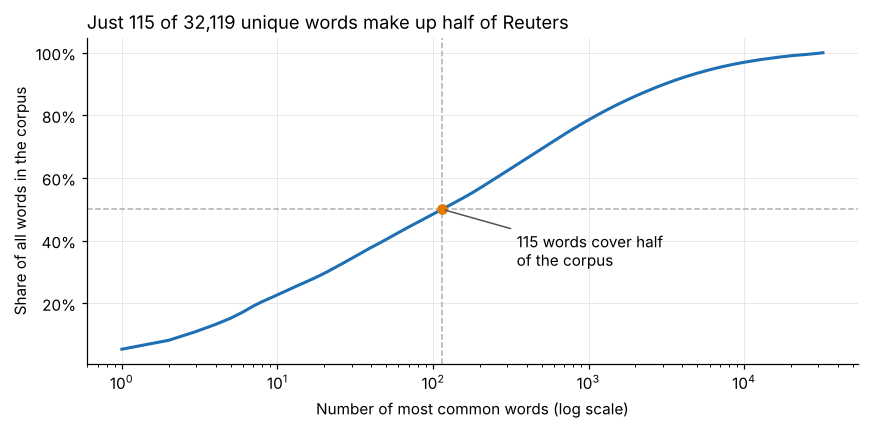

In [7]:
freq = pd.DataFrame(counts.most_common(), columns=["word", "count"])
freq["rank"] = np.arange(1, len(freq) + 1)
freq["rel_freq"] = freq["count"] / total
freq["cum_share"] = freq["count"].cumsum() / total
half_n = int((freq["cum_share"] >= 0.5).idxmax()) + 1

# Same calculation with stopwords removed, for comparison
ns = freq[~freq["word"].isin(stops)].copy()
ns["cum_share"] = ns["count"].cumsum() / ns["count"].sum()
half_ns = int(np.argmax(ns["cum_share"].values >= 0.5)) + 1

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(freq["rank"], freq["cum_share"], color=BLUE, lw=2)
ax.axhline(0.5, color=GREY, lw=1, ls="--")
ax.axvline(half_n, color=GREY, lw=1, ls="--")
ax.scatter([half_n], [0.5], color=ORANGE, zorder=3)
ax.annotate(f"{half_n} words cover half\nof the corpus", (half_n, 0.5), xytext=(half_n * 3, 0.32),
            arrowprops=dict(arrowstyle="-", color="#555"), fontsize=10)
ax.set_xscale("log")
ax.set_xlabel("Number of most common words (log scale)")
ax.set_ylabel("Share of all words in the corpus")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title(f"Just {half_n} of {len(freq):,} unique words make up half of Reuters", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

In [8]:
display(Markdown(
    f"**Answer: {half_n} unique words** ({half_n / len(freq):.2%} of the vocabulary) account for half of the "
    f"{total:,} words in the corpus. Most of them are function words such as \"the,\" \"of\" and \"to,\" "
    f"but the list already includes Reuters shorthand like \"mln,\" \"dlrs\" and \"pct.\" If stopwords "
    f"are removed first, it takes {half_ns:,} words to cover half of what remains, because content words "
    "are spread over a much larger vocabulary."))

**Answer: 115 unique words** (0.36% of the vocabulary) account for half of the 1,292,829 words in the corpus. Most of them are function words such as "the," "of" and "to," but the list already includes Reuters shorthand like "mln," "dlrs" and "pct." If stopwords are removed first, it takes 317 words to cover half of what remains, because content words are spread over a much larger vocabulary.

# 4. The 200 most frequent words

The table lists the top 200 words with their count and relative frequency (count divided by all
words in the corpus), in two tables of 100 (ranks 1–100, then 101–200), each split into two side-by-side blocks of 50.

In [9]:
top200 = freq.head(200).copy()
top200["pct"] = (top200["rel_freq"] * 100).map("{:.2f}%".format)

for half in range(2):
    blocks = []
    for b in range(half * 2, half * 2 + 2):
        chunk = top200.iloc[b * 50:(b + 1) * 50][["rank", "word", "count", "pct"]].reset_index(drop=True)
        chunk.columns = ["Rank", "Word", "Count", "Share of all words"]
        blocks.append(chunk)
    show_table(pd.concat(blocks, axis=1))

|   Rank | Word    |   Count | Share of all words   |   Rank | Word       |   Count | Share of all words   |
|-------:|:--------|--------:|:---------------------|-------:|:-----------|--------:|:---------------------|
|      1 | the     |   69247 | 5.36%                |     51 | were       |    3092 | 0.24%                |
|      2 | of      |   36749 | 2.84%                |     52 | trade      |    3064 | 0.24%                |
|      3 | to      |   36280 | 2.81%                |     53 | had        |    2975 | 0.23%                |
|      4 | in      |   29217 | 2.26%                |     54 | profit     |    2939 | 0.23%                |
|      5 | and     |   25629 | 1.98%                |     55 | about      |    2812 | 0.22%                |
|      6 | said    |   25382 | 1.96%                |     56 | market     |    2790 | 0.22%                |
|      7 | a       |   24841 | 1.92%                |     57 | new        |    2707 | 0.21%                |
|      8 | mln     |   18608 | 1.44%                |     58 | qtr        |    2672 | 0.21%                |
|      9 | vs      |   14341 | 1.11%                |     59 | shares     |    2652 | 0.21%                |
|     10 | for     |   13465 | 1.04%                |     60 | stock      |    2625 | 0.20%                |
|     11 | dlrs    |   12414 | 0.96%                |     61 | one        |    2539 | 0.20%                |
|     12 | it      |   11100 | 0.86%                |     62 | also       |    2532 | 0.20%                |
|     13 | pct     |    9784 | 0.76%                |     63 | they       |    2528 | 0.20%                |
|     14 | on      |    9094 | 0.70%                |     64 | tonnes     |    2510 | 0.19%                |
|     15 | cts     |    8361 | 0.65%                |     65 | revs       |    2312 | 0.18%                |
|     16 | from    |    8217 | 0.64%                |     66 | two        |    2278 | 0.18%                |
|     17 | is      |    7668 | 0.59%                |     67 | sales      |    2215 | 0.17%                |
|     18 | that    |    7540 | 0.58%                |     68 | prices     |    2194 | 0.17%                |
|     19 | its     |    7402 | 0.57%                |     69 | up         |    2191 | 0.17%                |
|     20 | by      |    7082 | 0.55%                |     70 | group      |    2112 | 0.16%                |
|     21 | at      |    7015 | 0.54%                |     71 | may        |    2110 | 0.16%                |
|     22 | net     |    6987 | 0.54%                |     72 | been       |    2070 | 0.16%                |
|     23 | year    |    6771 | 0.52%                |     73 | per        |    2058 | 0.16%                |
|     24 | be      |    6354 | 0.49%                |     74 | march      |    2030 | 0.16%                |
|     25 | with    |    6179 | 0.48%                |     75 | april      |    2011 | 0.16%                |
|     26 | will    |    5951 | 0.46%                |     76 | after      |    1958 | 0.15%                |
|     27 | was     |    5816 | 0.45%                |     77 | more       |    1881 | 0.15%                |
|     28 | billion |    5811 | 0.45%                |     78 | first      |    1881 | 0.15%                |
|     29 | u.s     |    5656 | 0.44%                |     79 | japan      |    1879 | 0.15%                |
|     30 | he      |    5210 | 0.40%                |     80 | rate       |    1845 | 0.14%                |
|     31 | loss    |    5115 | 0.40%                |     81 | co         |    1840 | 0.14%                |
|     32 | has     |    4864 | 0.38%                |     82 | price      |    1794 | 0.14%                |
|     33 | would   |    4671 | 0.36%                |     83 | quarter    |    1788 | 0.14%                |
|     34 | company |    4661 | 0.36%                |     84 | than       |    1771 | 0.14%                |
|     35 | an      |    4556 | 0.35%                |     85 | february   |    1771 | 0.14%                |
|     36 | as      |    4526 | 0.35%                |     86 | offer      |    1717 | 0.13%                |
|     37 | not     |    4386 | 0.34%                |     87 | government |    1706 | 0.13%                |
|     38 | shr     |    4180 | 0.32%                |     88 | january    |    1689 | 0.13%                |
|     39 | inc     |    4121 | 0.32%                |     89 | other      |    1653 | 0.13%                |
|     40 | which   |    3666 | 0.28%                |     90 | dollar     |    1627 | 0.13%                |
|     41 | bank    |    3625 | 0.28%                |     91 | week       |    1601 | 0.12%                |
|     42 | but     |    3601 | 0.28%                |     92 | exchange   |    1599 | 0.12%                |
|     43 | this    |    3516 | 0.27%                |     93 | note       |    1584 | 0.12%                |
|     44 | corp    |    3397 | 0.26%                |     94 | if         |    1555 | 0.12%                |
|     45 | last    |    3228 | 0.25%                |     95 | agreement  |    1550 | 0.12%                |
|     46 | or      |    3224 | 0.25%                |     96 | against    |    1492 | 0.12%                |
|     47 | are     |    3215 | 0.25%                |     97 | no         |    1490 | 0.12%                |
|     48 | oil     |    3205 | 0.25%                |     98 | could      |    1468 | 0.11%                |
|     49 | have    |    3107 | 0.24%                |     99 | production |    1456 | 0.11%                |
|     50 | share   |    3102 | 0.24%                |    100 | today      |    1445 | 0.11%                |

|   Rank | Word          |   Count | Share of all words   |   Rank | Word        |   Count | Share of all words   |
|-------:|:--------------|--------:|:---------------------|-------:|:------------|--------:|:---------------------|
|    101 | we            |    1441 | 0.11%                |    151 | months      |    1022 | 0.08%                |
|    102 | ltd           |    1440 | 0.11%                |    152 | into        |    1020 | 0.08%                |
|    103 | told          |    1427 | 0.11%                |    153 | end         |    1017 | 0.08%                |
|    104 | foreign       |    1425 | 0.11%                |    154 | money       |    1015 | 0.08%                |
|    105 | some          |    1422 | 0.11%                |    155 | banks       |    1008 | 0.08%                |
|    106 | international |    1420 | 0.11%                |    156 | major       |    1000 | 0.08%                |
|    107 | over          |    1410 | 0.11%                |    157 | department  |     983 | 0.08%                |
|    108 | three         |    1374 | 0.11%                |    158 | ec          |     976 | 0.08%                |
|    109 | expected      |    1373 | 0.11%                |    159 | cash        |     975 | 0.08%                |
|    110 | their         |    1370 | 0.11%                |    160 | american    |     970 | 0.08%                |
|    111 | rose          |    1366 | 0.11%                |    161 | officials   |     969 | 0.07%                |
|    112 | interest      |    1361 | 0.11%                |    162 | spokesman   |     969 | 0.07%                |
|    113 | rise          |    1322 | 0.10%                |    163 | report      |     962 | 0.07%                |
|    114 | rates         |    1319 | 0.10%                |    164 | japanese    |     957 | 0.07%                |
|    115 | total         |    1318 | 0.10%                |    165 | made        |     956 | 0.07%                |
|    116 | under         |    1307 | 0.10%                |    166 | now         |     953 | 0.07%                |
|    117 | current       |    1306 | 0.10%                |    167 | investment  |     951 | 0.07%                |
|    118 | record        |    1293 | 0.10%                |    168 | west        |     948 | 0.07%                |
|    119 | there         |    1282 | 0.10%                |    169 | imports     |     946 | 0.07%                |
|    120 | dlr           |    1279 | 0.10%                |    170 | buy         |     946 | 0.07%                |
|    121 | all           |    1265 | 0.10%                |    171 | mths        |     946 | 0.07%                |
|    122 | nine          |    1263 | 0.10%                |    172 | countries   |     944 | 0.07%                |
|    123 | stg           |    1224 | 0.09%                |    173 | analysts    |     942 | 0.07%                |
|    124 | tax           |    1216 | 0.09%                |    174 | december    |     938 | 0.07%                |
|    125 | exports       |    1210 | 0.09%                |    175 | acquisition |     938 | 0.07%                |
|    126 | five          |    1196 | 0.09%                |    176 | while       |     935 | 0.07%                |
|    127 | oper          |    1192 | 0.09%                |    177 | business    |     932 | 0.07%                |
|    128 | official      |    1176 | 0.09%                |    178 | any         |     925 | 0.07%                |
|    129 | increase      |    1171 | 0.09%                |    179 | operations  |     923 | 0.07%                |
|    130 | world         |    1169 | 0.09%                |    180 | when        |     921 | 0.07%                |
|    131 | growth        |    1159 | 0.09%                |    181 | stake       |     920 | 0.07%                |
|    132 | board         |    1152 | 0.09%                |    182 | financial   |     919 | 0.07%                |
|    133 | month         |    1137 | 0.09%                |    183 | national    |     919 | 0.07%                |
|    134 | six           |    1137 | 0.09%                |    184 | th          |     912 | 0.07%                |
|    135 | meeting       |    1112 | 0.09%                |    185 | pay         |     909 | 0.07%                |
|    136 | added         |    1108 | 0.09%                |    186 | agreed      |     907 | 0.07%                |
|    137 | avg           |    1086 | 0.08%                |    187 | yen         |     898 | 0.07%                |
|    138 | earnings      |    1082 | 0.08%                |    188 | says        |     895 | 0.07%                |
|    139 | shrs          |    1078 | 0.08%                |    189 | four        |     895 | 0.07%                |
|    140 | between       |    1076 | 0.08%                |    190 | united      |     895 | 0.07%                |
|    141 | because       |    1076 | 0.08%                |    191 | fell        |     894 | 0.07%                |
|    142 | common        |    1064 | 0.08%                |    192 | further     |     887 | 0.07%                |
|    143 | sale          |    1062 | 0.08%                |    193 | cut         |     882 | 0.07%                |
|    144 | earlier       |    1059 | 0.08%                |    194 | central     |     881 | 0.07%                |
|    145 | export        |    1041 | 0.08%                |    195 | sources     |     877 | 0.07%                |
|    146 | industry      |    1040 | 0.08%                |    196 | due         |     871 | 0.07%                |
|    147 | unit          |    1039 | 0.08%                |    197 | deficit     |     868 | 0.07%                |
|    148 | dividend      |    1037 | 0.08%                |    198 | companies   |     864 | 0.07%                |
|    149 | wheat         |    1026 | 0.08%                |    199 | down        |     863 | 0.07%                |
|    150 | economic      |    1022 | 0.08%                |    200 | around      |     859 | 0.07%                |

In [10]:
covered = top200["count"].sum() / total
in_stops = top200["word"].isin(stops).sum()
display(Markdown(
    f"Together, the top 200 words make up **{covered:.0%} of all words** in the corpus. "
    f"{in_stops} of them are NLTK stopwords. The rest are dominated by finance and business vocabulary: "
    "units (\"mln,\" \"billion,\" \"dlrs,\" \"pct,\" \"cts\"), earnings-table words (\"shr,\" \"net,\" "
    "\"vs,\" \"qtr,\" \"revs\"), company words (\"inc,\" \"corp,\" \"company,\" \"shares\") and "
    "commodities and markets (\"oil,\" \"bank,\" \"trade,\" \"market,\" \"prices\")."))

Together, the top 200 words make up **57% of all words** in the corpus. 59 of them are NLTK stopwords. The rest are dominated by finance and business vocabulary: units ("mln," "billion," "dlrs," "pct," "cts"), earnings-table words ("shr," "net," "vs," "qtr," "revs"), company words ("inc," "corp," "company," "shares") and commodities and markets ("oil," "bank," "trade," "market," "prices").

# 5. Relative frequency of the top 200 words

Each bar is one word's share of all words in the corpus, in rank order. To set up question 7,
words are colored **blue when they're at least five times more common in Reuters than in the
Brown corpus** of general English, and grey otherwise.

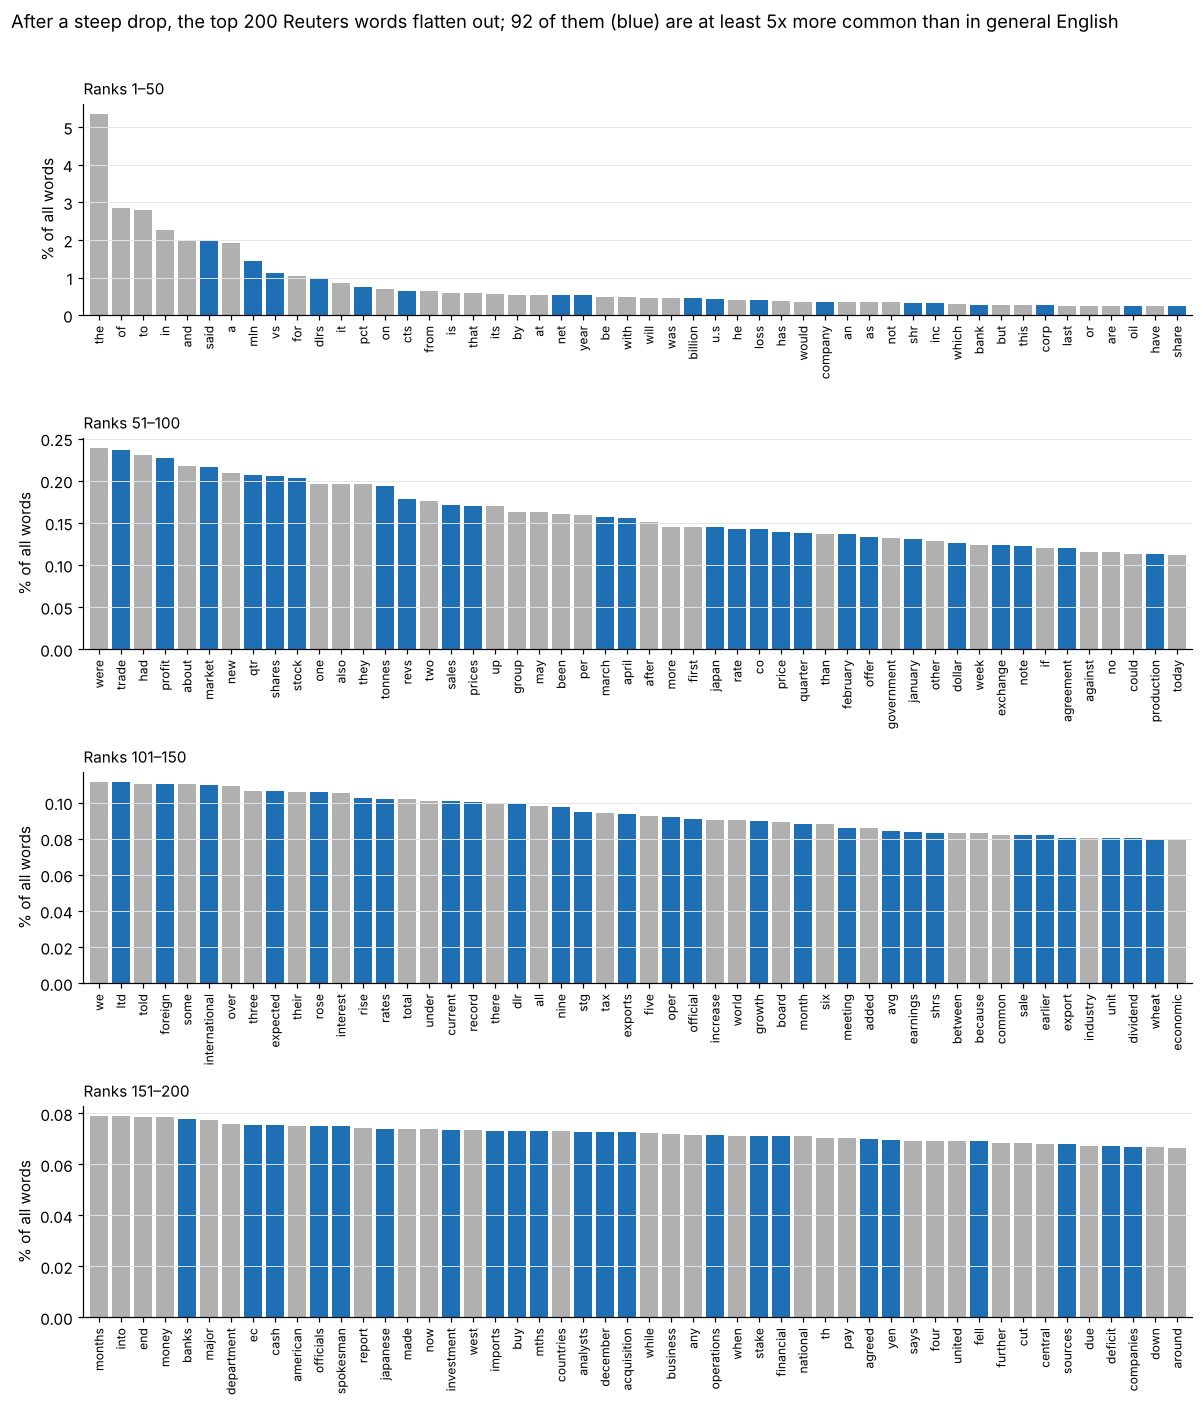

In [11]:
brown_tokens = tokenize(" ".join(brown.words()))
brown_counts = Counter(brown_tokens)
brown_total = len(brown_tokens)

def ratio(w):
    # relative frequency in Reuters / relative frequency in Brown (add-one smoothing for words Brown lacks)
    return (counts[w] / total) / ((brown_counts.get(w, 0) + 1) / brown_total)

top200["ratio_vs_brown"] = top200["word"].map(ratio)
top200["distinctive"] = top200["ratio_vs_brown"] >= 5
n_dist = int(top200["distinctive"].sum())

fig, axes = plt.subplots(4, 1, figsize=(11, 13))
for b, ax in enumerate(axes):
    chunk = top200.iloc[b * 50:(b + 1) * 50]
    colors = np.where(chunk["distinctive"], BLUE, GREY)
    ax.bar(range(len(chunk)), chunk["rel_freq"] * 100, color=colors, width=0.8)
    ax.set_xticks(range(len(chunk)))
    ax.set_xticklabels(chunk["word"], rotation=90, fontsize=8)
    ax.set_xlim(-0.7, 49.7)
    ax.set_ylabel("% of all words")
    ax.grid(axis="x", visible=False)
    ax.set_title(f"Ranks {b*50+1}–{b*50+50}", loc="left", fontsize=10)
fig.suptitle(f"After a steep drop, the top 200 Reuters words flatten out; {n_dist} of them (blue) are "
             "at least 5x more common than in general English", x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

In [12]:
display(Markdown(
    f"The first panel shows the classic shape: \"the\" alone is {top200.loc[0, 'rel_freq']:.1%} of all words, "
    f"and by rank 50 a word is down to about {top200.loc[49, 'rel_freq']:.2%}. "
    "Each panel has its own y-axis, because on a shared axis the last three panels would be nearly flat. "
    f"**{n_dist} of the top 200 words** are blue. They show up at every rank, from \"mln\" and \"dlrs\" near "
    "the top to words like \"tonnes\" and \"dividend\" further down."))

The first panel shows the classic shape: "the" alone is 5.4% of all words, and by rank 50 a word is down to about 0.24%. Each panel has its own y-axis, because on a shared axis the last three panels would be nearly flat. **92 of the top 200 words** are blue. They show up at every rank, from "mln" and "dlrs" near the top to words like "tonnes" and "dividend" further down.

# 6. Does the corpus follow Zipf's law?

Zipf's law says a word's frequency is roughly inversely proportional to its rank: the 2nd most
common word appears about half as often as the 1st, the 10th about a tenth as often, and so on.
In symbols, $f(r) \approx C / r^{s}$ with $s \approx 1$. On a log-log plot of frequency against rank
that's a straight line with slope $-1$.

I check this three ways: plot rank against frequency on log-log axes with a slope $-1$ reference line,
fit the slope by least squares, and check whether rank × frequency stays roughly constant.

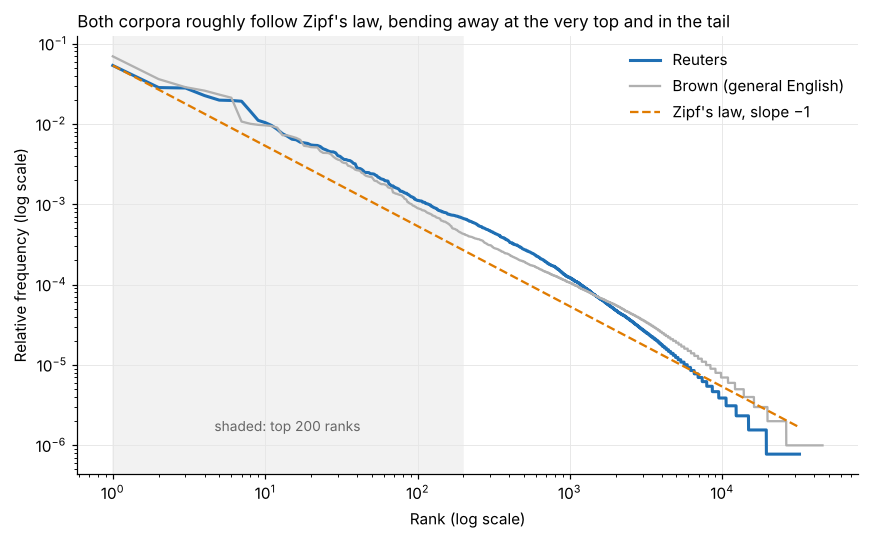

In [13]:
def fit_slope(df, lo, hi):
    d = df[(df["rank"] >= lo) & (df["rank"] <= hi)]
    slope, intercept = np.polyfit(np.log10(d["rank"]), np.log10(d["rel_freq"]), 1)
    return slope

slope_200 = fit_slope(freq, 1, 200)
slope_body = fit_slope(freq, 10, 5000)

brown_freq = pd.DataFrame(brown_counts.most_common(), columns=["word", "count"])
brown_freq["rank"] = np.arange(1, len(brown_freq) + 1)
brown_freq["rel_freq"] = brown_freq["count"] / brown_total
brown_slope_200 = fit_slope(brown_freq, 1, 200)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(freq["rank"], freq["rel_freq"], color=BLUE, lw=2, label="Reuters")
ax.loglog(brown_freq["rank"], brown_freq["rel_freq"], color=GREY, lw=1.5, label="Brown (general English)")
r = np.array([1, len(freq)])
ax.loglog(r, freq["rel_freq"].iloc[0] / r, color=ORANGE, ls="--", lw=1.5, label="Zipf's law, slope −1")
ax.axvspan(1, 200, color="#f2f2f2", zorder=0)
ax.text(14, 1.5e-6, "shaded: top 200 ranks", color="#666", fontsize=9, ha="center")
ax.set_xlabel("Rank (log scale)"); ax.set_ylabel("Relative frequency (log scale)")
ax.legend(frameon=False)
ax.set_title("Both corpora roughly follow Zipf's law, bending away at the very top and in the tail",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()

In [14]:
check = freq.set_index("rank").loc[[1, 2, 3, 5, 10, 20, 50, 100, 150, 200], ["word", "count", "rel_freq"]]
check["rank × freq"] = check.index * check["rel_freq"]
check["Zipf predicts"] = check["rel_freq"].iloc[0] / check.index
show_table(check.reset_index().assign(
    rel_freq=lambda d: d["rel_freq"].map("{:.4f}".format),
    **{"rank × freq": lambda d: d["rank × freq"].map("{:.3f}".format),
       "Zipf predicts": lambda d: d["Zipf predicts"].map("{:.4f}".format)}))

|   rank | word     |   count |   rel_freq |   rank × freq |   Zipf predicts |
|-------:|:---------|--------:|-----------:|--------------:|----------------:|
|      1 | the      |   69247 |     0.0536 |         0.054 |          0.0536 |
|      2 | of       |   36749 |     0.0284 |         0.057 |          0.0268 |
|      3 | to       |   36280 |     0.0281 |         0.084 |          0.0179 |
|      5 | and      |   25629 |     0.0198 |         0.099 |          0.0107 |
|     10 | for      |   13465 |     0.0104 |         0.104 |          0.0054 |
|     20 | by       |    7082 |     0.0055 |         0.11  |          0.0027 |
|     50 | share    |    3102 |     0.0024 |         0.12  |          0.0011 |
|    100 | today    |    1445 |     0.0011 |         0.112 |          0.0005 |
|    150 | economic |    1022 |     0.0008 |         0.119 |          0.0004 |
|    200 | around   |     859 |     0.0007 |         0.133 |          0.0003 |

In [15]:
display(Markdown(f"""
**Answer: roughly yes, with the usual departures.** The fitted log-log slope for the top 200 words is
**{slope_200:.2f}**, against Zipf's ideal of −1 (Brown's top 200 give {brown_slope_200:.2f}). Over ranks 10
to 5,000 the slope is {slope_body:.2f}. So across the top 200, frequency falls off with rank at close to the
rate Zipf's law predicts. On the chart, the blue line sits above the orange reference (because the very top
is flatter, see below), then falls a little faster than it and meets it near rank 10,000. Over four orders of
magnitude the line stays within a factor of about 2.7 of the reference.

The fit isn't perfect, in three places:

- **The very top is flatter than Zipf predicts.** \"of\" and \"to\" (ranks 2 and 3) appear more often than
  1/2 and 1/3 of \"the,\" so rank × frequency rises from {check['rank × freq'].iloc[0]:.3f} at rank 1 to about 0.10–0.13 from rank 10 on,
  instead of staying constant. This is common in English.
- **The middle of the top 200 has bumps.** Words from earnings tables (\"vs,\" \"cts,\" \"shr,\" \"net\")
  are pushed up the ranking because thousands of short earnings reports repeat the same template. A corpus
  made of a single genre bends the curve this way.
- **The tail drops off faster than the line.** Past a few thousand words the curve falls more steeply,
  and the last {len(hapax):,} words are a flat step of words used only once. That's partly a sample-size
  effect: a corpus of 1.3 million words can't show the rare words a larger sample would contain.
"""))


**Answer: roughly yes, with the usual departures.** The fitted log-log slope for the top 200 words is
**-0.93**, against Zipf's ideal of −1 (Brown's top 200 give -1.04). Over ranks 10
to 5,000 the slope is -1.22. So across the top 200, frequency falls off with rank at close to the
rate Zipf's law predicts. On the chart, the blue line sits above the orange reference (because the very top
is flatter, see below), then falls a little faster than it and meets it near rank 10,000. Over four orders of
magnitude the line stays within a factor of about 2.7 of the reference.

The fit isn't perfect, in three places:

- **The very top is flatter than Zipf predicts.** "of" and "to" (ranks 2 and 3) appear more often than
  1/2 and 1/3 of "the," so rank × frequency rises from 0.054 at rank 1 to about 0.10–0.13 from rank 10 on,
  instead of staying constant. This is common in English.
- **The middle of the top 200 has bumps.** Words from earnings tables ("vs," "cts," "shr," "net")
  are pushed up the ranking because thousands of short earnings reports repeat the same template. A corpus
  made of a single genre bends the curve this way.
- **The tail drops off faster than the line.** Past a few thousand words the curve falls more steeply,
  and the last 12,672 words are a flat step of words used only once. That's partly a sample-size
  effect: a corpus of 1.3 million words can't show the rare words a larger sample would contain.


# 7. How does this corpus differ from "all words in all corpora"?

There's no true "all corpora," so I use the Brown corpus as the stand-in for general English. It was
also compiled from American text (published in 1961) and covers 15 genres, from press reports to
fiction. Comparing relative frequencies, word by word, shows what is special about financial news.

In [16]:
both = pd.DataFrame({"reuters": pd.Series(counts), "brown": pd.Series(brown_counts)}).fillna(0)
both["reuters_rel"] = both["reuters"] / total
both["brown_rel"] = both["brown"] / brown_total
# Log ratio with add-one smoothing, only for words common enough to compare (50+ uses combined)
# and at least 3 letters long (drops stray initials and abbreviations such as "af")
common = both[((both["reuters"] + both["brown"]) >= 50) & (both.index.str.len() >= 3)].copy()
common["log2_ratio"] = np.log2(((common["reuters"] + 1) / total) / ((common["brown"] + 1) / brown_total))

def fmt(d):
    out = d.reset_index().rename(columns={"index": "word"})
    return pd.DataFrame({
        "Word": out["word"],
        "Reuters per 10k": (out["reuters_rel"] * 1e4).map("{:.1f}".format),
        "Brown per 10k": (out["brown_rel"] * 1e4).map("{:.1f}".format),
        "Ratio": (2 ** out["log2_ratio"]).map(lambda x: f"{x:,.0f}x" if x >= 1 else f"1/{1/x:,.0f}"),
    })

over = common.sort_values("log2_ratio", ascending=False).head(15)
under = common.sort_values("log2_ratio").head(15)
display(Markdown("**Words much more common in Reuters than in general English**"))
show_table(fmt(over))
display(Markdown("**Words much less common in Reuters than in general English**"))
show_table(fmt(under))

**Words much more common in Reuters than in general English**

| Word   |   Reuters per 10k |   Brown per 10k | Ratio   |
|:-------|------------------:|----------------:|:--------|
| mln    |             143.9 |               0 | 14,470x |
| dlrs   |              96   |               0 | 9,654x  |
| pct    |              75.7 |               0 | 7,609x  |
| cts    |              64.7 |               0 | 6,502x  |
| shr    |              32.3 |               0 | 3,251x  |
| qtr    |              20.7 |               0 | 2,078x  |
| tonnes |              19.4 |               0 | 1,952x  |
| revs   |              17.9 |               0 | 1,799x  |
| dlr    |               9.9 |               0 | 995x    |
| stg    |               9.5 |               0 | 953x    |
| oper   |               9.2 |               0 | 928x    |
| avg    |               8.4 |               0 | 845x    |
| shrs   |               8.3 |               0 | 839x    |
| mths   |               7.3 |               0 | 736x    |
| div    |               5.3 |               0 | 534x    |

**Words much less common in Reuters than in general English**

| Word      |   Reuters per 10k |   Brown per 10k | Ratio   |
|:----------|------------------:|----------------:|:--------|
| her       |               0.1 |            30.2 | 1/355   |
| boy       |               0   |             2.6 | 1/333   |
| mother    |               0   |             2.5 | 1/325   |
| woman     |               0   |             2.4 | 1/318   |
| girl      |               0   |             2.3 | 1/297   |
| god       |               0   |             3.5 | 1/228   |
| husband   |               0   |             1.5 | 1/192   |
| girls     |               0   |             1.4 | 1/186   |
| eyes      |               0   |             4   | 1/172   |
| beautiful |               0   |             1.3 | 1/165   |
| religion  |               0   |             1.2 | 1/154   |
| gun       |               0   |             1.2 | 1/154   |
| church    |               0   |             3.5 | 1/153   |
| doctor    |               0   |             1.2 | 1/153   |
| poet      |               0   |             1.1 | 1/145   |

In [17]:
brown_top200 = set(brown_freq.head(200)["word"])
overlap = len(set(top200["word"]) & brown_top200)
stop_share_r = sum(c for w, c in counts.items() if w in stops) / total
stop_share_b = sum(c for w, c in brown_counts.items() if w in stops) / brown_total
brown_cum = brown_freq["count"].cumsum() / brown_total
brown_half = int(np.argmax(brown_cum.values >= 0.5)) + 1
pron = ["i", "me", "my", "we", "you", "he", "him", "his", "she", "her"]
pron_r = sum(counts[w] for w in pron) / total
pron_b = sum(brown_counts[w] for w in pron) / brown_total

summary = pd.DataFrame({
    "Measure": ["Total words", "Unique words (lowercased)", "Words covering half the corpus",
                "Top-200 words shared by both corpora", "Share of words that are stopwords",
                "Share of words that are personal pronouns (I, me, my, we, you, he, him, his, she, her)"],
    "Reuters": [f"{total:,}", f"{len(counts):,}", f"{half_n}", f"{overlap} of 200",
                f"{stop_share_r:.0%}", f"{pron_r:.1%}"],
    "Brown": [f"{brown_total:,}", f"{len(brown_counts):,}", f"{brown_half}", f"{overlap} of 200",
              f"{stop_share_b:.0%}", f"{pron_b:.1%}"],
})
show_table(summary)

| Measure                                                                                | Reuters   | Brown     |
|:---------------------------------------------------------------------------------------|:----------|:----------|
| Total words                                                                            | 1,292,829 | 1,005,266 |
| Unique words (lowercased)                                                              | 32,119    | 45,487    |
| Words covering half the corpus                                                         | 115       | 125       |
| Top-200 words shared by both corpora                                                   | 76 of 200 | 76 of 200 |
| Share of words that are stopwords                                                      | 34%       | 48%       |
| Share of words that are personal pronouns (I, me, my, we, you, he, him, his, she, her) | 0.7%      | 3.9%      |

In [18]:
display(Markdown(f"""
**Answer.** The comparison shows five main differences:

1. **A specialized vocabulary takes over the top ranks.** Only {overlap} of the top 200 Reuters words are
   also in Brown's top 200. Words such as \"mln,\" \"dlrs,\" \"pct,\" \"cts\" and \"shr\" are among the most
   common words in Reuters but almost never appear in general English. These are Reuters' house abbreviations
   for million, dollars, percent, cents and share.
2. **Templates repeat.** Thousands of earnings reports follow the same layout (\"Shr 22 cts vs 18 cts ... Net
   ... Revs ...\"), so a handful of template words get far more weight than they would in varied writing.
   It takes {half_n} words to cover half of Reuters against {brown_half} for Brown, even though Reuters is the
   larger corpus, and Reuters has fewer unique words ({len(counts):,} vs {len(brown_counts):,}). Both point the same
   way: financial news reuses a smaller vocabulary.
3. **Fewer personal pronouns.** Personal pronouns are {pron_r:.1%} of Reuters but {pron_b:.1%} of Brown.
   Newswire reports what organizations and officials \"said\" (the 6th most common word); it has no
   characters or narrators, so \"I,\" \"you,\" \"she\" and \"her\" are rare. The most under-represented words are about
   people and private life: \"her,\" \"mother,\" \"girl,\" \"husband,\" \"eyes,\" \"church.\"
4. **Numbers, place names and companies.** Numbers make up {n_numbers / (total + n_numbers):.0%} of tokens,
   and words like \"u.s,\" \"japan,\" \"inc\" and \"corp\" are far more common than in general text. The long
   tail is full of ticker codes, which general English wouldn't have at all.
5. **The time period.** The stories are from 1987, so the vocabulary reflects that year's news: OPEC and
   crude oil, the U.S.–Japan trade dispute, and Bundesbank and Federal Reserve policy. A financial corpus
   from today would have different topical words (crypto, inflation, AI) even though the template words
   would probably remain.

The very top of the list is shared: \"the,\" \"of,\" \"to,\" \"and,\" \"a\" and \"in\" are the six most
common words in Brown and among the seven most common in Reuters. That part of the distribution seems close to
universal for English. Below it the corpora split apart. Stopwords are only {stop_share_r:.0%} of Reuters against
{stop_share_b:.0%} of Brown, because so much of a financial story is units, abbreviations, company names and
numbers rather than connecting words.
"""))


**Answer.** The comparison shows five main differences:

1. **A specialized vocabulary takes over the top ranks.** Only 76 of the top 200 Reuters words are
   also in Brown's top 200. Words such as "mln," "dlrs," "pct," "cts" and "shr" are among the most
   common words in Reuters but almost never appear in general English. These are Reuters' house abbreviations
   for million, dollars, percent, cents and share.
2. **Templates repeat.** Thousands of earnings reports follow the same layout ("Shr 22 cts vs 18 cts ... Net
   ... Revs ..."), so a handful of template words get far more weight than they would in varied writing.
   It takes 115 words to cover half of Reuters against 125 for Brown, even though Reuters is the
   larger corpus, and Reuters has fewer unique words (32,119 vs 45,487). Both point the same
   way: financial news reuses a smaller vocabulary.
3. **Fewer personal pronouns.** Personal pronouns are 0.7% of Reuters but 3.9% of Brown.
   Newswire reports what organizations and officials "said" (the 6th most common word); it has no
   characters or narrators, so "I," "you," "she" and "her" are rare. The most under-represented words are about
   people and private life: "her," "mother," "girl," "husband," "eyes," "church."
4. **Numbers, place names and companies.** Numbers make up 7% of tokens,
   and words like "u.s," "japan," "inc" and "corp" are far more common than in general text. The long
   tail is full of ticker codes, which general English wouldn't have at all.
5. **The time period.** The stories are from 1987, so the vocabulary reflects that year's news: OPEC and
   crude oil, the U.S.–Japan trade dispute, and Bundesbank and Federal Reserve policy. A financial corpus
   from today would have different topical words (crypto, inflation, AI) even though the template words
   would probably remain.

The very top of the list is shared: "the," "of," "to," "and," "a" and "in" are the six most
common words in Brown and among the seven most common in Reuters. That part of the distribution seems close to
universal for English. Below it the corpora split apart. Stopwords are only 34% of Reuters against
48% of Brown, because so much of a financial story is units, abbreviations, company names and
numbers rather than connecting words.


# Summary

In [19]:
summary_rows = pd.DataFrame({
    "Question": ["Corpus", "Unique words", "Words covering half the corpus", "Top 200 words",
                 "Zipf's law", "Difference from general English"],
    "Answer": [
        f"Reuters-21578 (NLTK ApteMod): {len(docs):,} financial news stories from 1987",
        f"{len(lower):,} lowercased words; between {repeated:,} and {len(case_kept):,} depending on the definition",
        f"{half_n} words cover half of the {total:,} words",
        f"{covered:.0%} of all words; {in_stops} are stopwords, most of the rest are finance and business terms",
        f"Roughly followed: slope {slope_200:.2f} for the top 200; flatter at the very top, steeper in the tail",
        "Specialized abbreviations, repeated earnings templates, few personal pronouns, many numbers and company names, 1987 topics",
    ]})
show_table(summary_rows)

| Question                        | Answer                                                                                                                     |
|:--------------------------------|:---------------------------------------------------------------------------------------------------------------------------|
| Corpus                          | Reuters-21578 (NLTK ApteMod): 10,788 financial news stories from 1987                                                      |
| Unique words                    | 32,119 lowercased words; between 19,447 and 42,831 depending on the definition                                             |
| Words covering half the corpus  | 115 words cover half of the 1,292,829 words                                                                                |
| Top 200 words                   | 57% of all words; 59 are stopwords, most of the rest are finance and business terms                                        |
| Zipf's law                      | Roughly followed: slope -0.93 for the top 200; flatter at the very top, steeper in the tail                                |
| Difference from general English | Specialized abbreviations, repeated earnings templates, few personal pronouns, many numbers and company names, 1987 topics |

**Limitations.** The results depend on the tokenizing choices (for example, keeping "u.s" as one word and
dropping numbers). Brown is only a proxy for "all corpora" and is itself 1961 American English. The corpus
covers only stories that were given topic labels, and earnings and acquisition stories make up most of it,
so the results describe that mix of financial news rather than financial writing in general.